### Analysis Report- Nov 15th
### Jangila Rockland 


#### Part 1
* For this project, I chose a dataset from JSONLint's Free JSON Datasets link.  I chose a JSON file that had information on World Airports. 
* https://jsonlint.com/datasets/airports 
* I chose this dataset because I like to travel around the world. This dataset can provide information on which airports are potentially the best international travel hotspots. 
* Each observation represents an individual major airport around the world. This includes its airport code, name, city, country, and coordinates.
* The variables that I plan to investigate are: "lat" and "lon" to measure the location of the airport. I will also use the variable "Country," which ties in with the coordinates. I am going to create a variable to measure the distance of each airport to the others in the file to discover which airport is most centrally located. 
##### Research Question and Hypothesis:
* Research question: Which airports have a location that is closest to other major airport hubs? Do international airports sit closer to one another than airports in the United States?
* Hypothesis: Major airports in countries other than the United States, more specifically Europe, sit closer to other airports than US airports do, serving as easier travel hotspot destinations.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("airports.json")

display(df.head())
print(df.columns)

,airports
0,"{'code': 'ATL', 'name': 'Hartsfield-Jackson At..."
1,"{'code': 'PEK', 'name': 'Beijing Capital Inter..."
2,"{'code': 'DXB', 'name': 'Dubai International',..."
3,"{'code': 'LAX', 'name': 'Los Angeles Internati..."
4,"{'code': 'HND', 'name': 'Tokyo Haneda', 'city'..."


Index(['airports'], dtype='str')


* I started by doing this as we did in our last class when you showed us how to plot the music streaming JSON. This displayed in a not pretty way. From doing this I see that everything is trapped inside of dictionaries so next I will have to unpack and understand what is within each of these columns. 

In [14]:
df = pd.json_normalize(df["airports"])
display(df.head())

,code,name,city,country,lat,lon
0,ATL,Hartsfield-Jackson Atlanta International,Atlanta,US,33.6407,-84.4277
1,PEK,Beijing Capital International,Beijing,CN,40.0801,116.5846
2,DXB,Dubai International,Dubai,AE,25.2528,55.3644
3,LAX,Los Angeles International,Los Angeles,US,33.9425,-118.4081
4,HND,Tokyo Haneda,Tokyo,JP,35.5494,139.7798


* By using the line pd.json_normalize(), I pull each dictionary key into its own table column. This allows me to display my DataFrame in the way that I first intended, which is much cleaner. We did this in our in class demo on 11/9. 

In [15]:
print(df.shape)
df.info()
print(df.isna().sum())

(30, 6)
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   code     30 non-null     str    
 1   name     30 non-null     str    
 2   city     30 non-null     str    
 3   country  30 non-null     str    
 4   lat      30 non-null     float64
 5   lon      30 non-null     float64
dtypes: float64(2), str(4)
memory usage: 2.6 KB
code       0
name       0
city       0
country    0
lat        0
lon        0
dtype: int64


* I did this to make sure I have enough data for this assignment, and to see the data types. 

In [16]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


### Part 2

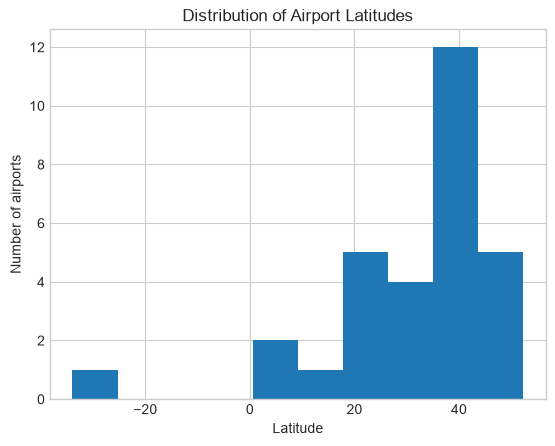

In [17]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.hist(df["lat"], bins=10)
plt.title("Distribution of Airport Latitudes")
plt.xlabel("Latitude")
plt.ylabel("Number of airports")

    
plt.show()
 


*  What does the distribution look like? : The distribution is left-skewed and most concentrated at around 40 degrees latitude. Almost all of the airports have positive lattitudes, meaning they are in the Northern hemisphere. 
* Are there any unusual values or patterns? : The one airport with a negative latitude of about -30 is an outlier in this data. There is a large gap separating this from all the others, showing that it is the only airport in this data that is in the Southern Hemisphere. Also, since this chart is not displaying country names or longitude, we cannot find the exact locations, so we are unable to make a claim about how close these airports truly are to one another.
* How does your choice of bins affect the visualizations? : Using bins (10) makes the data easier to see/interpret since you can clearly see the distribution and outliers. If I were to do bins (5), my data would be wayyy too generalized since each chunk is very large. On the other hand, raising it to 100 would create tons of tiny bars.

* after seeing what styles I had available I chose one that fit well for this histogram.

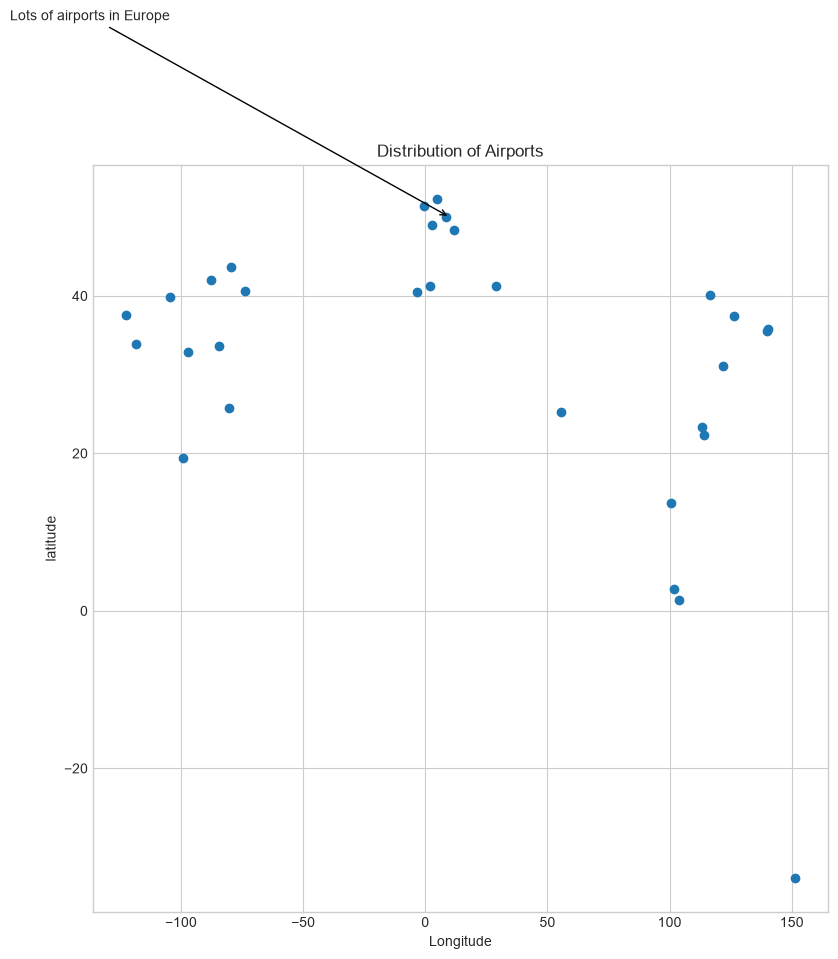

In [27]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(8, 8))
plt.annotate("Lots of airports in Europe", xy=(10, 50), xytext=(-170, 75),
             arrowprops=dict(arrowstyle="->"))
plt.tight_layout()
plt.scatter( df["lon"], df["lat"])
plt.title("Distribution of Airports")
plt.xlabel("Longitude")
plt.ylabel("latitude")

plt.show()

* By having this data shown in a scatter plot, I can understand and interpret my data much more easily. Both latitude and longitude are being used, so now I can visualize where the airports tend to clump. I can now see that there is a cluster of airports in the -110/-60 longitude, the 0-10 longitude, and a more dispersed cluster in the 100-125 longitude. I can also still see the outlier that I have at around (150,-30).

* I wasn't sure how to add the annotation on my own so I needed some help from Claude in terms of formatting and adding the arrow so it was more visable

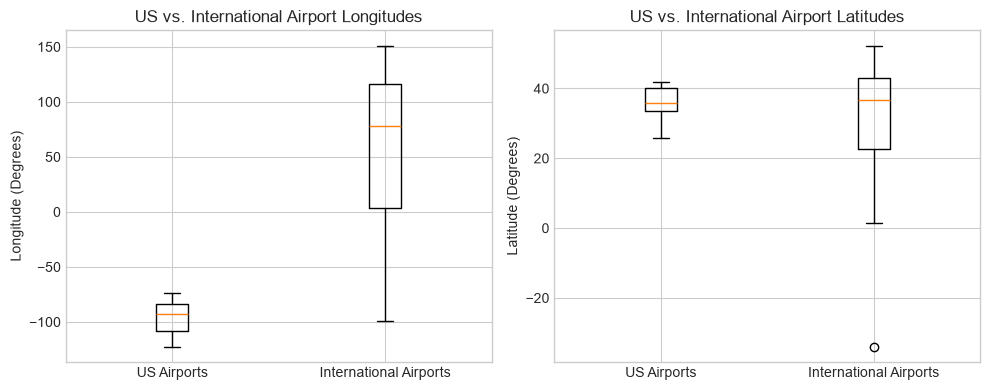

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

us = df[df["country"] == "US"]
intl = df[df["country"] != "US"]

axes[0].boxplot([us["lon"], intl["lon"]], tick_labels=["US Airports", "International Airports"])
axes[0].set_title("US vs. International Airport Longitudes")
axes[0].set_ylabel("Longitude (Degrees)")

axes[1].boxplot([us["lat"], intl["lat"]], tick_labels=["US Airports", "International Airports"])
axes[1].set_title("US vs. International Airport Latitudes")
axes[1].set_ylabel("Latitude (Degrees)")

plt.tight_layout()
plt.show()

* By seperating the airports into US and International airports I am able to compare each group more easily and understand how spread out they are. The us has a smaller plot which means it has a smaller range. this is probably due to the close priximity of each state. the median sits ar about -90 longitde. For the international airports this has a much larger range with the median at about 78 longitude. This is because the data for international airports is spread between multiple continents. Looking at these by country would be much more helpful. 

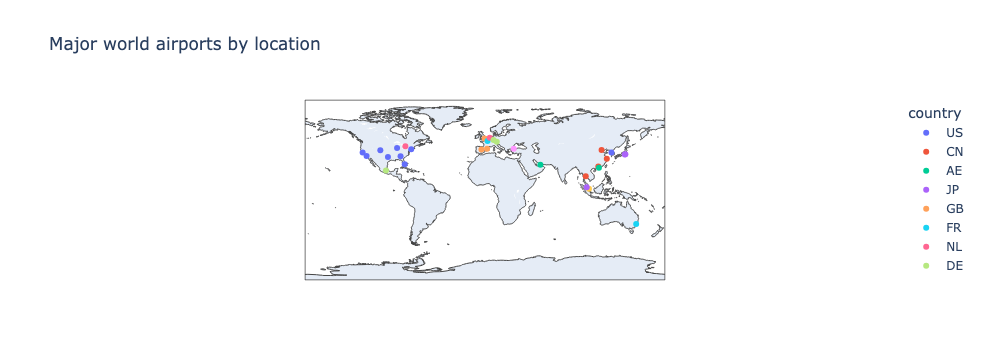

In [20]:
import plotly.express as px

fig = px.scatter_geo(
    df,
    lat="lat",
    lon="lon",
    hover_name="name",
    hover_data=["code", "city", "country"],
    color="country",
    title="Major world airports by location"
    
)
fig.show()

* We used Plotly previously in class. I thought this would be a great tool for visualizing this data, as I can see where each airport is on the map by country. Each country is in its own color, which makes it very easy to distinguish, and the hover feature allows for insight into specific coordinate locations.
* Seeing as my scatter plot was the easiest of the three options to understand, I wanted to improve that visualization to be more interactive and clear.

* I just realized that this didn't count for part 3, but I did it anyway :) 

### Part 3

#### Changes I made to improve visualization:

* I applied "plt.style.use("seaborn-v0_8-whitegrid")" on my figures so my charts appear more clean and cohesiive. They all have a white background with a grid which allows for easier readibility.
* I used figsize in my scatter plot and boxplot to alter the dimensions of my visualizations.
* I also used plt.tight_layout() this was so the points have enough room where they will not overlap and all are clearly visable.
* I added an annotation with plt.annotate() onto my scatter plot with an arrow so it was easily visable and hilighted the clustered section in the data. This is significant in my research question and hypothesis as the area is showing as a potentially best for easy acessible travel.

* I also misunderstood the directions originally and made a chart using plotly. I beleive this was the best way to visualize my data in a way that shows to be easily interpreted and interactive.

### Part 4
 #### Option A- Compare two groups using ols()

In [30]:
from statsmodels.formula.api import ols

df["is_us"] = (df["country"] == "US").astype(int)
model = ols("lon ~ is_us", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    lon   R-squared:                       0.548
Model:                            OLS   Adj. R-squared:                  0.532
Method:                 Least Squares   F-statistic:                     33.95
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           2.92e-06
Time:                        22:27:01   Log-Likelihood:                -166.19
No. Observations:                  30   AIC:                             336.4
Df Residuals:                      28   BIC:                             339.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.3175     13.597      4.215      0.0

* variables: Dependent-"lon", independent variable-"is_us"
* Coefficents: the coefficents are 57.3175 and -153.4301. This can be interpreted as the airports are on average 153.43 degrees west. which does not seem very relevent.
* P values: the P values are .000 meaning that the difference is statistically significant between the longitude of us and international airports. this is since it is less than .05
* Does the result support my hypothesis? It somewhat shows that airports are concentrated in the western hemisphere but it doesnt prove how close all of these 'international travel hubs' are. 

* Overall statistical analysis: Us airports are tightly clustered near eachother, while international airports have a larger range. There are some limitations as cinparing the longitude measures position rather than distance between all airports. Also I am grouping all non US airports togehter which totally throws off the sample. 


### Part 5- Conclusion
* What did you learn from analyzing your dataset? : By analyzing my data set I learned how to display data in all sorts of different ways to fit my intended hypothesis. In this example I learned how different airports are clustered in different regions of the world. 

* Did your findings support your original hypothesis? Which visualization was most effective in communicating your results? Why? : They mostly supported my hypothesis. I think my scatter plot and plotly map were most helpful in making general assumptions with data. This helped show which areas grouped together best, I think if I had more time with this assignment it would really help tp have each country seperated into their own groups, rather than having the US vs all other countries. 

* What limitations exist in your dataset or analysis? : This data set did not include every single airport. It only included 30 airports which may have thrown off my hypothesis. Also as I said before, it would have been much more helpful to have grouped each country indivisually. 

* What information might your analysis fail to capture? What additional data or alternative approaches might improve your investigation? : My analysis fails to capture the traffic of these airpots or ticket prices. Without these vairables it is hard to make generalizations for what areas are 'best'. Since that is something that is already subjective I would need to have those variables to make claims such as "best affordable travel countries" or "the busiest airports within 'set proximity*' of one another. 

